<h1>
<Center>
Tugas Pendahuluan
</Center>
</h1>

Nama    : Rafael Hartono

NIM     : 24031554166


# 1.1 Persiapan & Perkenalan Lingkungan

myenv

In [1]:
!uv pip install -r requirements.txt

Using Python 3.12.13 environment at: /home/rafael/Documents/graf_24031554166/myenv
Checked 8 packages in 2ms


# 1.2 Mempelajari Penggunaan Driver Neo4J

In [2]:
# !docker run --name neo4j-local -p 7474:7474 -p 7687:7687 -e NEO4J_AUTH=neo4j/password -d neo4j:latest
!docker start neo4j-local

neo4j-local


In [3]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password")

In [4]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

In [6]:
# menghapus secara bertahap untuk memastikan kode database awal kalau pakai cara biasanya stuck di Out of Memory
query_count = "MATCH (n) RETURN count(n) AS total"
query_clean = """
MATCH (n)
CALL (n) {
    DETACH DELETE n
} IN TRANSACTIONS OF 10000 ROWS
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:

        result = session.run(query_count)
        total_nodes = result.single()["total"]


        if total_nodes > 0:
            print(
                f"Ditemukan {total_nodes:,} node. Memulai proses"
                " pembersihan..."
            )
            session.run(query_clean)
            print("Pembersihan selesai! Semua node berhasil dihapus.")
        else:
            print("Database sudah kosong, tidak ada data yang perlu dihapus.")

Ditemukan 4 node. Memulai proses pembersihan...
Pembersihan selesai! Semua node berhasil dihapus.


In [7]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
    "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
    "RETURN friend.name ORDER BY friend.name",
    name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


1. Apa nama database yang digunakan pada tutorial ini?

jawab: neo4j

In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:

    records, _, _ = driver.execute_query(
        "SHOW DATABASES",
        database_="system"
    )
    
    print("--- Daftar Database di Instance Neo4j ---")
    for record in records:
        print(f"Nama: {record['name']} | Tipe: {record['type']} | Status: {record['currentStatus']} | Default: {record['default']}")

--- Daftar Database di Instance Neo4j ---
Nama: neo4j | Tipe: standard | Status: online | Default: True
Nama: system | Tipe: system | Status: online | Default: False


2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!

jawab:

USE system

SHOW DATABASES;

.

CREATE DATABASE data1; #hanya saja neo4j gratisan belum support create lebih dari 1 database

STOP DATABASE data1;

DROP DATABASE data1;

.

GRANT READ ON DATABASE neo4j TO role_analyst;

DENY ACCESS ON DATABASE data1 TO role_admin;


3. Apa jenis graf pertemnanan yang telah dibuat di sini?

In [9]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:

    records, _, _ = driver.execute_query(
        "MATCH (n) RETURN n;",
        database_="neo4j"
    )
    
    print("--- Daftar Database di Instance Neo4j ---")
    for record in records:
        print(record["n"])

--- Daftar Database di Instance Neo4j ---
<Node element_id='4:6ebdb75f-43f5-4fb0-b4a6-6f7676db1efe:4' labels=frozenset({'Person'}) properties={'name': 'Arthur'}>
<Node element_id='4:6ebdb75f-43f5-4fb0-b4a6-6f7676db1efe:5' labels=frozenset({'Person'}) properties={'name': 'Guinevere'}>
<Node element_id='4:6ebdb75f-43f5-4fb0-b4a6-6f7676db1efe:6' labels=frozenset({'Person'}) properties={'name': 'Lancelot'}>
<Node element_id='4:6ebdb75f-43f5-4fb0-b4a6-6f7676db1efe:7' labels=frozenset({'Person'}) properties={'name': 'Merlin'}>


![Visualisasi Graf Tugas](<visualisasi graf tugas.png>)



Pada graf ini menunjukan bentuk graf pertemanan satu arah yang berbentuk bintang dimana Arthur menjadi pusatnya

In [10]:


with GraphDatabase.driver(URI, auth=AUTH) as driver:

    records, _, _ = driver.execute_query(
        "MATCH(n)DETACH DELETE n",
        database_="neo4j"
    )
    
    print("--- Daftar Database di Instance Neo4j ---")
    for record in records:
        print(record["n"])

--- Daftar Database di Instance Neo4j ---


# 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

In [11]:
import os

if not os.path.exists("ecommerce-dataset.zip"):
    !curl -L -o ecommerce-dataset.zip \https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

    print("File ecommerce-dataset.zip berhasil didownload")

else:
    print("File ecommerce-dataset.zip sudah ada")

File ecommerce-dataset.zip sudah ada


In [12]:
import zipfile

with zipfile.ZipFile("ecommerce-dataset.zip", "r") as zip_ref:
    zip_ref.extractall("ecommerce-dataset")

print("File ecommerce-dataset berhasil diextract")

File ecommerce-dataset berhasil diextract


In [13]:
import pandas as pd

print(pd.__version__)

cat_tree = pd.read_csv("ecommerce-dataset/category_tree.csv")
print("Category Tree:")
print(cat_tree.head())

events = pd.read_csv("ecommerce-dataset/events.csv")
print("Events:")
print(events.head())

item_prop1 = pd.read_csv("ecommerce-dataset/item_properties_part1.csv")
print("Item Properties Part 1:")
print(item_prop1.head())

item_prop2 = pd.read_csv("ecommerce-dataset/item_properties_part2.csv")
print("Item Properties Part 2:")
print(item_prop2.head())

3.1.0
Category Tree:
   categoryid  parentid
0        1016     213.0
1         809     169.0
2         570       9.0
3        1691     885.0
4         536    1691.0
Events:
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
Item Properties Part 1:
       timestamp  itemid    property                            value
0  1435460400000  460429  categoryid                             1338
1  1441508400000  206783         888          1116713 960601 n277.200
2  1439089200000  395014         400  n552.000 639502 n720.000 424566
3  1431226800000   59481         790                       n15360.000
4  1431831600000  156781         917                           828513
Item Properties Part 2:
       timestamp 

In [14]:
from neo4j import GraphDatabase

uri = "neo4j://localhost:7687"
user = "neo4j"
password = "password"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

In [15]:
import argparse

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Import dataset RetailRocket (events.csv) ke database Neo4j" 
    )
    parser.add_argument(
        "-u",
        "--user",
        default="neo4j",
        help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="password",
        help="Password Neo4j (default: password)"   
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://localhost:7687",
        help="Neo4J URI / Bolt (default: neo4j://localhost:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="ecommerce-dataset",
        help="Direktori/folder sumber data (default: ecommerce-dataset)",
    )
    return parser.parse_known_args()[0]

In [16]:
import sys
args = parse_arguments()
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [17]:
try:
    driver = GraphDatabase.driver(
    args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e: 
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

In [18]:
from tqdm import tqdm

batch_size = 10000

def import_batch(tx, batch):
    cypher_query =  """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL ( v, i, row){
        WITH v, i, row WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId"
        " IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS"
        " UNIQUE"
    )

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = sum(1 for _ in open(csv_file_path, "r", encoding="utf-8")) - 1
    total_chunks = (total_rows // batch_size) + 1
    
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
    chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].astype(object).fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)
driver.close()
print("Proses impor berhasil.")

Membaca file data dari: ecommerce-dataset/events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [01:39<00:00,  2.79it/s]

Proses impor berhasil.


5 node viewed item
![visualisasi graf tugas_view-2.png](<attachment:visualisasi graf tugas_view-2.png>)
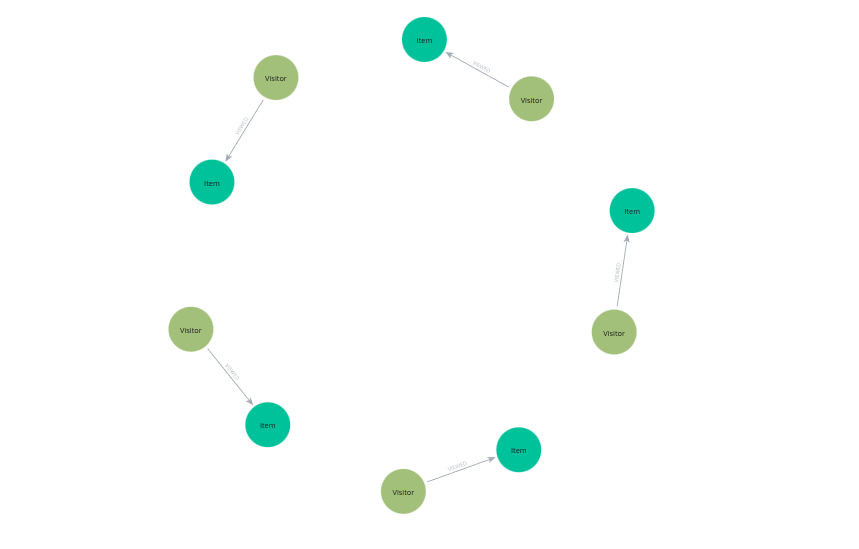

5 node bought item
![visualisasi graf tugas_bought.png](<attachment:visualisasi graf tugas_bought.png>)
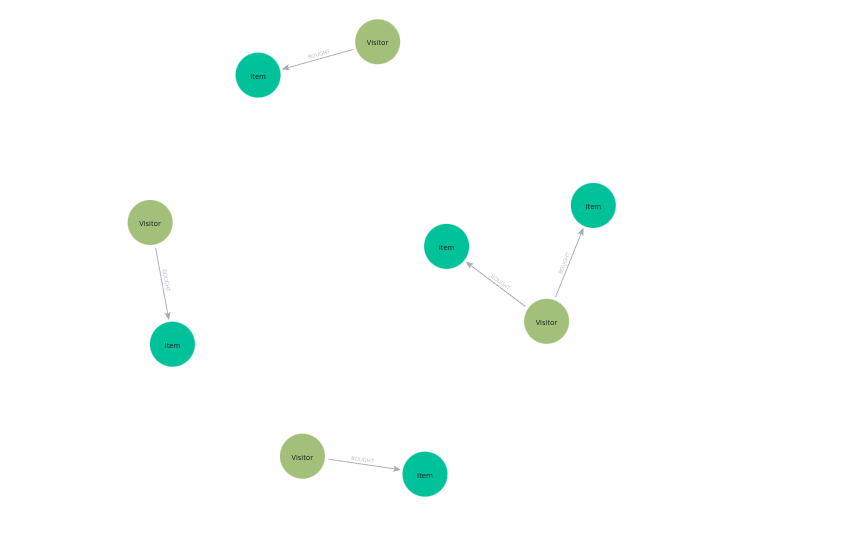

5 node added to cart item
![visualisasi graf tugas_cart.png](<attachment:visualisasi graf tugas_cart.png>)
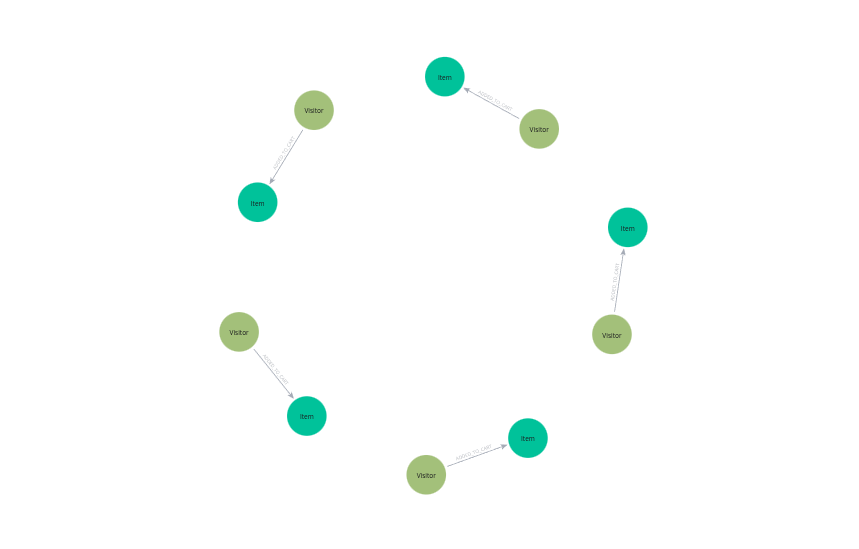